In [970]:
# Units are tracked (sorted on the concatenated recording), so the same unit_id
# is the same neuron in every condition. One figure per unit, conditions as columns:
# baseline -> aligned to movement peaks (contra/ipsi); stim -> aligned to stim onset.
# All rates go through the pipeline's edge-aware Gaussian path so they're comparable.

# Imports + config
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

import RCP_analysis as rcp
from RCP_analysis.python.functions.config_loading import *  # PARAMS, OUT_BASE, roots

%matplotlib inline

FS_INTAN = 30000.0
FS_VEL = 1000.0

WIN_PRE_S = 0.6
WIN_POST_S = 0.6
WIN_MS = (-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)

NPRW_RATES = PARAMS.NPRW_rate_est
BIN_MS = 30#float(NPRW_RATES.get("bin_ms", 20.0))
STEP_MS = 10 #float(NPRW_RATES.get("step_ms", BIN_MS))
SIGMA_MS = 30 #float(NPRW_RATES.get("sigma_ms", 20.0))
NORMALIZE_FIRST_MS = 150.0

# Stim blanking params
STIM_MS_BEFORE = float(NPRW_RATES.get("remove_ms_before", 20.0))
STIM_TAIL_MS = float(NPRW_RATES.get("remove_tail_ms_after", 20.0))

DATA_ROOT = Path(str(PARAMS.data_root))
SESSION_DIR = DATA_ROOT / Path(str(PARAMS.location))
SORT_RESULTS = SESSION_DIR / "results" / "checkpoints" / "sorting_results"
CAL_ROOT = SESSION_DIR / "Calibrated"

OUT_FIG_DIR = OUT_BASE / "figures" / "per_unit_cross_condition"
OUT_FIG_DIR.mkdir(parents=True, exist_ok=True)

In [971]:
# Conditions
CONDITIONS = [
    {
        "label": "Passive HoB",
        "kind": "baseline",
        "cal": CAL_ROOT / "IntanFile_1" / "BL_closed_loop_STIM_003_003_Cal.mat",
        "spikes": SORT_RESULTS / "BL_closed_loop_STIM_003_250528_140952" / "NPRW" / "spike_trains.mat",
        "peak_times_passive_ipsi": [17.579, 20.974, 24.119, 27.526, 31.043, 34.266, 37.244, 40.461, 43.869, 47.226],
        "peak_times_passive_contra": [16.2, 19.434, 22.518, 26.027, 29.263, 32.425, 35.59, 38.885, 41.978, 45.523, 49.915],
    },
    {
        "label": "Active HoB",
        "kind": "baseline",
        "cal": CAL_ROOT / "IntanFile_1" / "BL_closed_loop_STIM_003_004_Cal.mat",
        "spikes": SORT_RESULTS / "BL_closed_loop_STIM_003_250528_140952" / "NPRW" / "spike_trains.mat",
        "peak_times_active_ipsi": [14.146, 17.795, 21.477, 25.424, 29.449, 33.545, 37.44, 41.59],
        "peak_times_active_contra": [15.911, 19.723, 23.197, 27.366, 31.659, 35.227, 39.445],
        

    },
    {
        "label": "Active stim (BR_006)",
        "kind": "stim",
        "cal": CAL_ROOT / "IntanFile_3" / "BL_closed_loop_STIM_003_006_Cal_stim.mat",
        "spikes": SORT_RESULTS / "BL_closed_loop_STIM_003_250528_143802" / "NPRW" / "spike_trains.mat",
    },
    {
        "label": "Active stim (BR_007)",
        "kind": "stim",
        "cal": CAL_ROOT / "IntanFile_4" / "BL_closed_loop_STIM_003_007_Cal_stim.mat",
        "spikes": SORT_RESULTS / "BL_closed_loop_STIM_003_250528_144603" / "NPRW" / "spike_trains.mat",
    },
    {
        "label": "Active stim (BR_008)",
        "kind": "stim",
        "cal": CAL_ROOT / "IntanFile_5" / "BL_closed_loop_STIM_003_008_Cal_stim.mat",
        "spikes": SORT_RESULTS / "BL_closed_loop_STIM_003_250528_145904" / "NPRW" / "spike_trains.mat",
    },
]

In [972]:
SORT_RESULTS

PosixPath('/home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results')

In [973]:
# Helper functions
def load_spike_trains(path: Path) -> dict[int, np.ndarray]:
    """
    Load spike_trains .mat or .npz into a dictionary {unit_id: sample_indices}.

    Args:
        path: path to a spike_trains.mat or .npz file with per-unit spike
            sample indices stored under 'unit_<id>' keys.
    Returns:
        Dictionary mapping unit_id to its spike sample indices (int64),
        skipping non-unit fields such as fs.
    """
    trains = {}
    if path.suffix == ".npz":
        data = np.load(path, allow_pickle=True)
        items = ((k, data[k]) for k in data.files)
    else: #.mat
        data = loadmat(path, squeeze_me=True)
        items = ((k, v) for k, v in data.items())
    for k, v in items:
        if str(k).startswith("unit_"):  # skip fs and any non-unit fields
            uid = int(str(k).split("unit_")[1])
            trains[uid] = np.asarray(v, dtype=np.int64).ravel()
    return trains

def spike_times_s(unit_train: np.ndarray, intan_start: int) -> np.ndarray:
    """
    Convert spike samples to seconds relative to condition start.

    Args:
        unit_train: spike sample indices for one unit (from load_spike_trains).
        intan_start: sample index where this condition's Intan recording starts.
    Returns:
        Spike times in seconds, relative to intan_start (spikes before it dropped).
    """
    spk = np.asarray(unit_train, float)
    spk = spk[spk >= intan_start]  # drop spikes before this condition's recording start
    return (spk - intan_start) / FS_INTAN

VEL_THRESH = 85.0  # deg/s, matches MATLAB ±85 crossing rule

def detect_vel_crossings(vel, annot_times_s, direction,
                         search_pre_s=0.4, search_post_s=0.4, thresh=VEL_THRESH):
    """
    Find the true yaw-velocity threshold crossing near each manual annotation.

    For each annotation time, searches [annot-pre, annot+post] for the first
    crossing of ±thresh (upward through +thresh for 'pos'/ipsi, downward through
    -thresh for 'neg'/contra), matching the MATLAB pos_cross/neg_cross rule.
    Annotations with no crossing in-window are dropped; duplicate detections of
    the same crossing are removed.

    Args:
        vel: yaw velocity trace (deg/s) at FS_VEL.
        annot_times_s: manual reach annotation times in seconds.
        direction: 'pos' (ipsi, +thresh) or 'neg' (contra, -thresh).
        search_pre_s: window start before each annotation, in seconds.
        search_post_s: window end after each annotation, in seconds.
        thresh: velocity threshold in deg/s.
    Returns:
        Detected crossing times in seconds, sorted and de-duplicated.
    """
    vel = np.asarray(vel, float)
    # crossing sample indices (MATLAB: find(v(1:end-1)<T & v(2:end)>=T)+1)
    if direction == "pos":
        cross_idx = np.where((vel[:-1] < thresh) & (vel[1:] >= thresh))[0] + 1
    else:
        cross_idx = np.where((vel[:-1] > -thresh) & (vel[1:] <= -thresh))[0] + 1
    cross_t = cross_idx / FS_VEL

    detected = []
    for a in annot_times_s:
        in_win = cross_t[(cross_t >= a - search_pre_s) & (cross_t <= a + search_post_s)]
        if in_win.size:
            detected.append(in_win[0])  # first crossing in the window
    return np.unique(np.array(detected))  # sorted + de-duped

def get_gaussian_rates(spikes_s, events_s, ms_before, tail_ms):
    """
    Compute per-trial firing rates via the RCP edge-aware Gaussian path.

    Args:
        spikes_s: one unit's spike times in seconds (condition-relative).
        events_s: event times in seconds (stim onset or IR crossing).
        ms_before: blank window before each event, in ms (0 for baseline).
        tail_ms: blank window after each event, in ms (0 for baseline).
    Returns:
        rates_hz [n_trials, n_bins], rel_t_s (bin-center time axis in seconds).
    """
    # 0 event case
    if events_s.size == 0:
        return np.zeros((0, 0)), np.zeros(0)
    peaks_ms = {0: spikes_s * 1000.0}  # single-key dict: unit flows through rcp as one "channel"

    # Use RCP pipeline binning
    counts, rel_ms, widths, left_bins = rcp.bin_counts_around_stim(
        peaks_ms, BIN_MS, events_s * 1000.0, ms_before, tail_ms, WIN_MS, step_ms=STEP_MS,
    )

    # Use RCP pipeline edge-aware smoothing and per-trial baseline zero
    rates = rcp.smooth_counts_gauss(counts, widths, rel_ms, SIGMA_MS, left_bins)
    # rates = rcp.baseline_zero_each_trial(rates, rel_ms, normalize_first_ms=NORMALIZE_FIRST_MS)

    # RCP pipeline uses channels, so we are treating each neuron like a single channel here. We drop the neuron channel axis to get back out trials x time matrix
    return rates[:, 0, :], rel_ms / 1000.0


def plot_alignment(ax_raster, ax_psth, spikes_s, events_s, ms_before, tail_ms,
                   color, title, events_psth_s=None):
    """
    Raster + median PSTH for one alignment (one direction, one condition).

    Args:
        ax_raster: axis to draw the trial raster on.
        ax_psth: axis to draw the trial-median PSTH on.
        spikes_s: one unit's spike times in seconds (condition-relative).
        events_s: event times in seconds for the raster; one row per event.
        ms_before: blank window before each event, in ms (0 for baseline).
        tail_ms: blank window after each event, in ms (0 for baseline).
        color: line color for the PSTH.
        title: title for the raster axis (e.g. "Contra", "Ipsi").
        events_psth_s: event times for the PSTH average; if None, uses events_s
            (so raster and PSTH share trials). Pass the full, uncapped set to
            average over all trials while the raster stays capped.
    Returns:
        None. Plots are drawn onto the provided axes in place.
    """
    if events_psth_s is None:
        events_psth_s = events_s

    # PSTH from the (possibly larger) PSTH event set
    rates, rel_s = get_gaussian_rates(spikes_s, events_psth_s, ms_before, tail_ms)

    # Raster from the (possibly capped) raster event set; plot in ms
    for trial, trial_time_0 in enumerate(events_s):  # one raster row per event
        in_win = (spikes_s >= trial_time_0 - WIN_PRE_S) & (spikes_s <= trial_time_0 + WIN_POST_S)
        rel_ms = (spikes_s[in_win] - trial_time_0) * 1000.0
        ax_raster.plot(rel_ms, np.full(rel_ms.size, trial + 1), ".",
                       color=[0.3, 0.3, 0.3], markersize=3)
    ax_raster.axvline(0, color="r", ls="--", lw=1.2)  # event onset
    ax_raster.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
    ax_raster.set_ylim(0, max(1, events_s.size) + 1)
    ax_raster.set_ylabel("Trial")
    ax_raster.set_title(title, fontsize=9)
    if rates.size:
        ax_psth.plot(rel_s * 1000.0, np.nanmean(rates, axis=0), color=color, lw=1.3)  # median across trials
    ax_psth.axvline(0, color="r", ls="--", lw=1.2)
    ax_psth.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
    ax_psth.set_ylabel("FR (sp/s)")
    ax_psth.set_xlabel("Time (ms)")

In [974]:
# Load spike trains for every condition (run once)
# Same unit_id = same neuron across conditions (concatenated sort), so units share an ID space.
per_cond_trains = {cond["label"]: load_spike_trains(cond["spikes"]) for cond in CONDITIONS}
# Just take the neurons that exist in the first spike_train.mat file
available_units = sorted(per_cond_trains[CONDITIONS[0]["label"]].keys())
print(f"{len(available_units)} units across {len(CONDITIONS)} conditions")
print("units:", available_units)

140 units across 5 conditions
units: [6, 7, 8, 10, 11, 24, 28, 31, 37, 39, 40, 41, 43, 44, 46, 47, 48, 50, 52, 53, 54, 56, 58, 59, 60, 61, 62, 65, 66, 67, 68, 69, 71, 72, 73, 75, 77, 78, 79, 80, 81, 82, 83, 84, 86, 88, 89, 92, 94, 95, 96, 97, 98, 100, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 134, 135, 136, 137, 139, 141, 143, 146, 147, 149, 150, 151, 152, 154, 155, 156, 158, 159, 162, 163, 164, 165, 166, 168, 169, 170, 171, 172, 173, 174, 175, 176, 178, 179, 180, 181, 182, 184, 185, 186, 187, 188, 190, 191, 192, 193, 194, 197, 198, 199, 200, 201, 203, 206, 210, 215, 218, 226]


In [976]:
# Align spikes to Intan_idx ONCE, up front, per condition.
# Stores BOTH sample positions (for stitching) and seconds (for plots).
def align_unit_to_intan(unit_samples, intan_idx):
    """
    Returns (positions_in_recording, times_s):
      positions_in_recording: sample index within Intan_idx (int, for ua_ vectors)
      times_s: those positions in seconds (for peri-event analysis)
    """
    intan_idx = np.asarray(intan_idx, np.int64).ravel()
    _, idx_in_rec, _ = np.intersect1d(intan_idx, np.asarray(unit_samples, np.int64),
                                      return_indices=True)
    pos = np.sort(idx_in_rec)
    return pos, pos / FS_INTAN

aligned_pos = {}   # cond -> {uid: sample positions within Intan_idx}
aligned_spikes = {}  # cond -> {uid: spike times in seconds}
for cond in CONDITIONS:
    with h5py.File(str(cond["cal"]), "r") as f:
        intan_idx = np.asarray(f["Data"]["Intan_idx"]).ravel().astype(np.int64)
    aligned_pos[cond["label"]] = {}
    aligned_spikes[cond["label"]] = {}
    for uid, samples in per_cond_trains[cond["label"]].items():
        pos, t_s = align_unit_to_intan(samples, intan_idx)
        aligned_pos[cond["label"]][uid] = pos
        aligned_spikes[cond["label"]][uid] = t_s
    total = sum(v.size for v in aligned_spikes[cond["label"]].values())
    print(f"{cond['label']}: aligned {len(aligned_spikes[cond['label']])} units, {total} spikes")

Passive HoB: aligned 140 units, 105771 spikes
Active HoB: aligned 140 units, 152551 spikes
Active stim (BR_006): aligned 140 units, 289446 spikes
Active stim (BR_007): aligned 140 units, 259705 spikes
Active stim (BR_008): aligned 140 units, 318432 spikes


In [977]:
# Load Cal data and fields per condition
import h5py

def load_cal_fields(cal_path, kind):
    """
    Read Intan_idx, headYawVel, and (stim only) contra/ipsi peak times from a Cal file.

    Reading via h5py so we don't pull the whole large file into RAM. Stim Cal files
    have Data.segments.active_like_stim_pos/neg; baseline files don't (crossings are
    detected from manual annotations instead), so segments are skipped for baseline.
    Note: h5py returns MATLAB arrays transposed, so a MATLAB (n,2) matrix is (2,n)
    here and (:,1) -> raw[0,:].

    Args:
        cal_path: path to a v7.3 Cal .mat file with a 'Data' group.
        kind: "stim" (read segments) or "baseline" (skip segments).
    Returns:
        intan_start (first sample index), vel (head yaw velocity), pos_times,
        neg_times (peak times in ms for stim; None for baseline).
    """
    with h5py.File(str(cal_path), "r") as file:
        data = file["Data"]
        intan_start = int(np.asarray(data["Intan_idx"]).ravel()[0])  # condition's first sample index
        vel = np.asarray(data["headYawVel"], float).ravel()
        pos_times = neg_times = None
        if kind == "stim":
            seg = data["segments"]
            pos = np.asarray(seg["active_like_stim_pos"], float)
            neg = np.asarray(seg["active_like_stim_neg"], float)
            # row 0 = MATLAB column 1 = peak times (ms); guard the single-peak (1-D) case
            pos_times = pos[0, :] if pos.ndim == 2 else pos.ravel()
            neg_times = neg[0, :] if neg.ndim == 2 else neg.ravel()
    return intan_start, vel, pos_times, neg_times

cond_cache = {}  # per-condition data that doesn't change per unit; computed once
for cond in CONDITIONS:
    intan_start, vel, pos_times, neg_times = load_cal_fields(cond["cal"], cond["kind"])
    t_vel = np.arange(vel.size) / FS_VEL

    if cond["kind"] == "baseline":
        # detect true velocity crossings near each manual annotation (passive vs active keys)
        ipsi_annot = cond.get("peak_times_passive_ipsi") or cond.get("peak_times_active_ipsi") or []
        contra_annot = cond.get("peak_times_passive_contra") or cond.get("peak_times_active_contra") or []
        ipsi = detect_vel_crossings(vel, np.asarray(ipsi_annot, float), "pos")
        contra = detect_vel_crossings(vel, np.asarray(contra_annot, float), "neg")
        print(f"{cond['label']}: detected contra {contra.size}/{len(contra_annot)}, "
              f"ipsi {ipsi.size}/{len(ipsi_annot)} crossings")
    else:
        # stim: use segments peak times (contra from neg, ipsi from pos); ms -> s
        contra = neg_times / 1000.0
        ipsi = pos_times / 1000.0
        print(f"{cond['label']}: {contra.size} contra, {ipsi.size} ipsi (from segments)")

    events = {"contra": contra, "ipsi": ipsi}
    cond_cache[cond["label"]] = dict(
        intan_start=intan_start, vel=vel, t_vel=t_vel,
        kind=cond["kind"], events=events,
    )
    n_ev = sum(len(v) for v in events.values())
    print(f"  {cond['label']}: intan_start={intan_start}, {n_ev} events, vel {vel.size} samples")

Passive HoB: detected contra 11/11, ipsi 10/10 crossings
  Passive HoB: intan_start=3690135, 21 events, vel 53901 samples
Active HoB: detected contra 7/7, ipsi 8/8 crossings
  Active HoB: intan_start=6015514, 15 events, vel 67270 samples
Active stim (BR_006): 34 contra, 30 ipsi (from segments)
  Active stim (BR_006): intan_start=58116, 64 events, vel 222012 samples
Active stim (BR_007): 38 contra, 39 ipsi (from segments)
  Active stim (BR_007): intan_start=92175, 77 events, vel 258503 samples
Active stim (BR_008): 55 contra, 34 ipsi (from segments)
  Active stim (BR_008): intan_start=199125, 89 events, vel 379836 samples


In [978]:
# Save stitched Cal files: merge each unit's spike train into a copy of the Cal
# file as a MATLAB-readable field, using the pre-aligned positions from aligned_pos.
# Saves as <name>_stitched.mat next to the original. Originals never modified.
import shutil

def stitch_cal_file(cal_path, cond_label, units):
    """
    Copy a v7.3 Cal file and add each unit's spike sample positions (within
    Intan_idx) as a MATLAB-readable field, registered in Data's MATLAB_fields.

    Args:
        cal_path: path to the original v7.3 Cal .mat.
        cond_label: condition key into aligned_pos.
        units: unit ids to write.
    Returns:
        (out_path, n_added).
    """
    out_path = cal_path.with_name(cal_path.stem + "_stitched" + cal_path.suffix)
    shutil.copyfile(str(cal_path), str(out_path))

    vlen = h5py.special_dtype(vlen=np.uint8)
    pos_by_uid = aligned_pos[cond_label]

    with h5py.File(str(out_path), "r+") as f:
        data = f["Data"]

        if "MATLAB_fields" in data.attrs:
            existing = [bytes(x).decode("ascii") for x in data.attrs["MATLAB_fields"]]
        else:
            existing = [k for k in data.keys()]

        added = 0
        new_names = []
        for uid in units:
            pos = pos_by_uid.get(uid)
            if pos is None or pos.size == 0:
                continue
            name = f"unit_{uid}"
            if name in data:
                del data[name]
            arr = np.asarray(pos, np.int64).reshape(1, -1)  # MATLAB vector orientation
            dset = data.create_dataset(name, data=arr)
            dset.attrs["MATLAB_class"] = np.bytes_("int64")
            dset.attrs["MATLAB_int_decode"] = np.int64(8)
            if name not in existing:
                new_names.append(name)
            added += 1

        all_fields = existing + new_names
        field_arr = np.empty(len(all_fields), dtype=vlen)
        for i, nm in enumerate(all_fields):
            field_arr[i] = np.frombuffer(nm.encode("ascii"), dtype=np.uint8)
        if "MATLAB_fields" in data.attrs:
            del data.attrs["MATLAB_fields"]
        data.attrs.create("MATLAB_fields", field_arr)

    return out_path, added


print(f"Stitching {len(available_units)} units into {len(CONDITIONS)} Cal files\n")
for cond in CONDITIONS:
    # out_path, n_added = stitch_cal_file(cond["cal"], cond["label"], available_units)
    print(f"{cond['label']}: added {n_added} units -> {out_path.name}")
print("\nDone.")

Stitching 140 units into 5 Cal files

Passive HoB: added 109 units -> BL_closed_loop_STIM_003_008_Cal_stim_stitched.mat
Active HoB: added 109 units -> BL_closed_loop_STIM_003_008_Cal_stim_stitched.mat
Active stim (BR_006): added 109 units -> BL_closed_loop_STIM_003_008_Cal_stim_stitched.mat
Active stim (BR_007): added 109 units -> BL_closed_loop_STIM_003_008_Cal_stim_stitched.mat
Active stim (BR_008): added 109 units -> BL_closed_loop_STIM_003_008_Cal_stim_stitched.mat

Done.


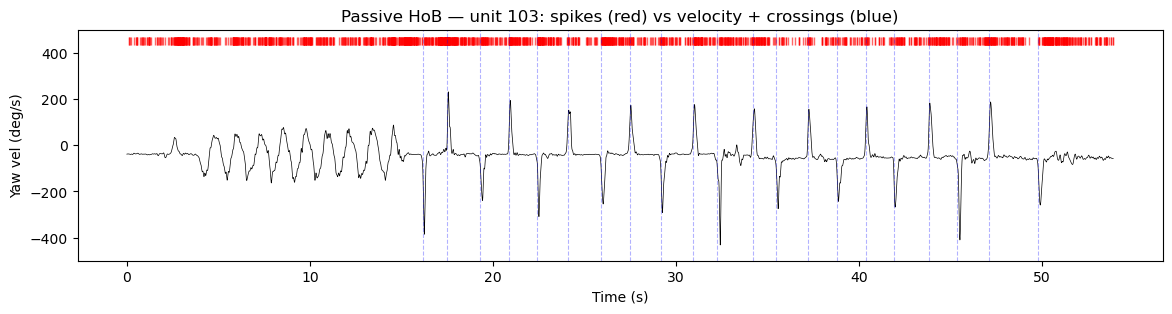

unit 103: 1929 spikes, recording 53.9s, vel span 53901 samples (53.9s)


In [979]:
# Test: do stitched spikes align to kinematics in the SAME file?
# Overlay a known movement-modulated unit's spikes on the velocity trace.
test_cond = CONDITIONS[0]
test_uid = 103  # a unit you know is movement-modulated from the per-unit figures

stitched_path = test_cond["cal"].with_name(test_cond["cal"].stem + "_stitched" + test_cond["cal"].suffix)

with h5py.File(str(stitched_path), "r") as f:
    data = f["Data"]
    vel = np.asarray(data["headYawVel"], float).ravel()
    unit_pos = np.asarray(data[f"unit_{test_uid}"]).ravel().astype(np.int64)  # positions within recording

# spikes are positions within Intan_idx at 30 kHz -> seconds; velocity is at FS_VEL
spk_s = unit_pos / FS_INTAN
t_vel = np.arange(vel.size) / FS_VEL

fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(t_vel, vel, color="k", lw=0.5)
ax.set_ylim(-500, 500)
# spike raster along the top
ax.plot(spk_s, np.full(spk_s.size, 450), "|", color="r", markersize=6, alpha=0.6)
# mark the detected crossings for this condition (from cond_cache, in seconds)
for p in np.concatenate([cond_cache[test_cond["label"]]["events"]["contra"],
                         cond_cache[test_cond["label"]]["events"]["ipsi"]]):
    ax.axvline(p, color="b", ls="--", alpha=0.3, lw=0.8)
ax.set_xlabel("Time (s)"); ax.set_ylabel("Yaw vel (deg/s)")
ax.set_title(f"{test_cond['label']} — unit {test_uid}: spikes (red) vs velocity + crossings (blue)")
plt.show()

print(f"unit {test_uid}: {spk_s.size} spikes, recording {t_vel[-1]:.1f}s, "
      f"vel span {vel.size} samples ({vel.size/FS_VEL:.1f}s)")

# Passive vs Active

In [983]:
print(available_units)

[6, 7, 8, 10, 11, 24, 28, 31, 37, 39, 40, 41, 43, 44, 46, 47, 48, 50, 52, 53, 54, 56, 58, 59, 60, 61, 62, 65, 66, 67, 68, 69, 71, 72, 73, 75, 77, 78, 79, 80, 81, 82, 83, 84, 86, 88, 89, 92, 94, 95, 96, 97, 98, 100, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 134, 135, 136, 137, 139, 141, 143, 146, 147, 149, 150, 151, 152, 154, 155, 156, 158, 159, 162, 163, 164, 165, 166, 168, 169, 170, 171, 172, 173, 174, 175, 176, 178, 179, 180, 181, 182, 184, 185, 186, 187, 188, 190, 191, 192, 193, 194, 197, 198, 199, 200, 201, 203, 206, 210, 215, 218, 226]


In [984]:
uid = 103

trial cap: contra n=7, ipsi n=8


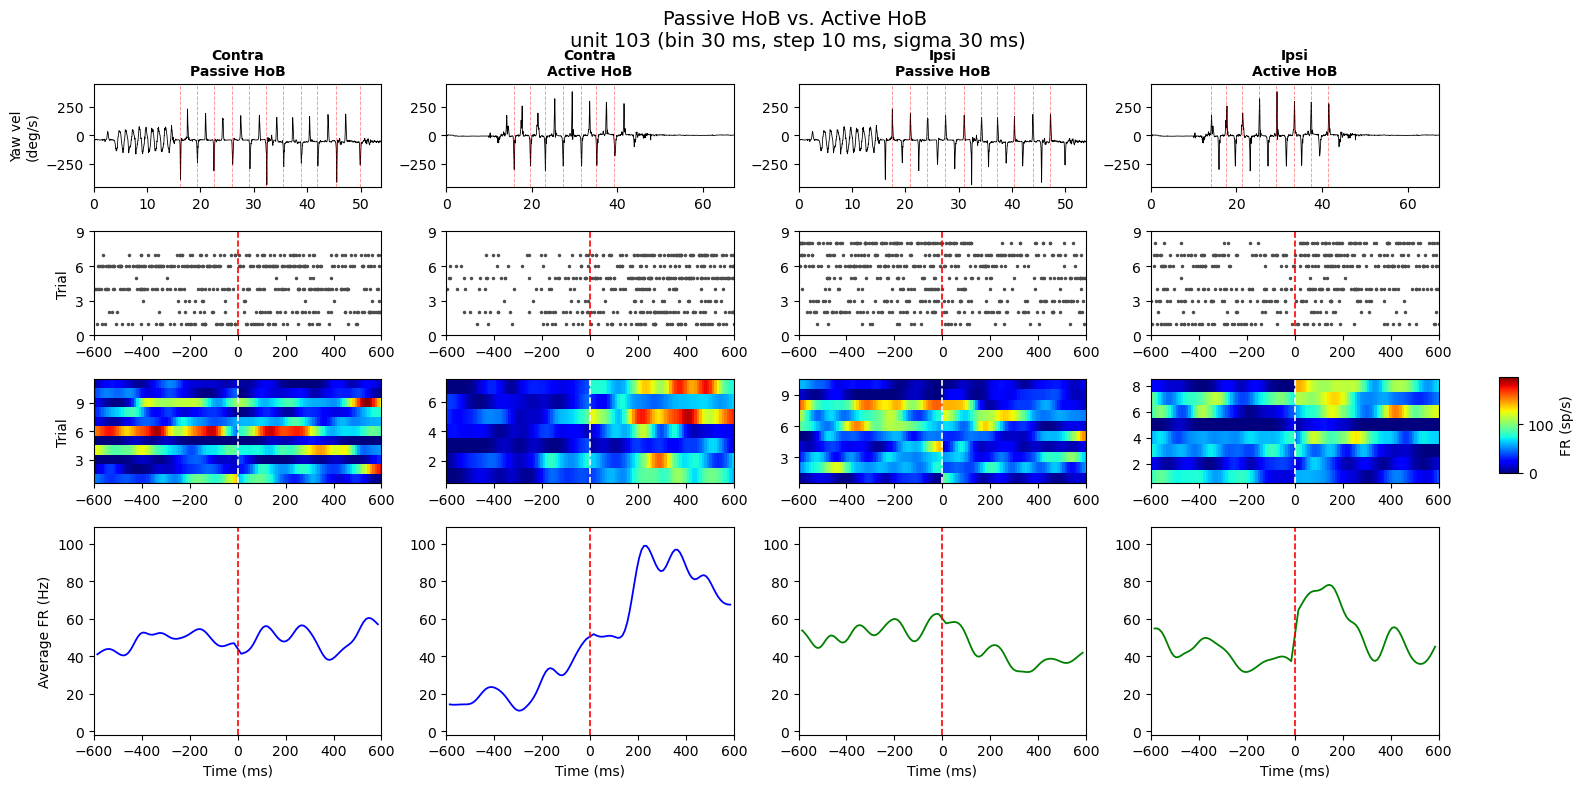

In [985]:
from matplotlib.ticker import MaxNLocator
# Plot ONE unit inline: contra and ipsi columns SIDE BY SIDE in one figure.
# Rows: 0 velocity trace, 1 raster (capped), 2 FR heatmap (all trials), 3 mean PSTH.
# Columns: [direction x condition], e.g. Contra-Passive, Contra-Active, Ipsi-Passive, Ipsi-Active.
# Y-axes and heatmap color scale locked per row across ALL columns for comparability.

plot_conds = [cond for cond in CONDITIONS if cond["label"] in ("Passive HoB", "Active HoB")]
assert plot_conds, "plot_conds is empty — check the labels match CONDITIONS exactly"

n_contra = min(cond_cache[cond["label"]]["events"]["contra"].size for cond in plot_conds)
n_ipsi   = min(cond_cache[cond["label"]]["events"]["ipsi"].size   for cond in plot_conds)
print(f"trial cap: contra n={n_contra}, ipsi n={n_ipsi}")

directions = [
    ("Contra", "contra", n_contra, "b"),
    ("Ipsi",   "ipsi",   n_ipsi,   "g"),
]

# One column per (direction, condition) pair, ordered direction-major.
columns = []
for dir_label, dir_key, n_cap, color in directions:
    for cond in plot_conds:
        columns.append(dict(dir_label=dir_label, dir_key=dir_key, n_cap=n_cap,
                            color=color, cond=cond))

n_cols = len(columns)
n_cap_raster = max(n_contra, n_ipsi)  # raster row height fits the larger cap

fig, axes = plt.subplots(
    4, n_cols, figsize=(4 * n_cols, 8), squeeze=False,
    gridspec_kw={"height_ratios": [1, 1, 1, 2]},  # vel, raster, heatmap, PSTH
)
last_im = None

# --- Pass 1: compute per-column data and track shared ranges (across all columns) ---
col_data = []
psth_max = 0.0
vel_absmax = 0.0
heat_max = 0.0
for col in columns:
    cc = cond_cache[col["cond"]["label"]]
    spk_s = aligned_spikes[cond["label"]].get(uid, np.zeros(0))
    events_full = cc["events"][col["dir_key"]]
    events_rast = events_full[:col["n_cap"]]
    msb, tail = (0.0, 0.0) if cc["kind"] == "baseline" else (STIM_MS_BEFORE, STIM_TAIL_MS)

    rates, rel_s = get_gaussian_rates(spk_s, events_full, msb, tail)  # [n_trials, n_bins]
    psth = np.nanmean(rates, axis=0) if rates.size else np.zeros(0)
    if psth.size:
        psth_max = max(psth_max, np.nanmax(psth))
    if rates.size:
        heat_max = max(heat_max, np.nanmax(rates))
    if cc["vel"].size:
        vel_absmax = max(vel_absmax, np.nanmax(np.abs(cc["vel"])))

    col_data.append(dict(col=col, cc=cc, spk_s=spk_s, events_full=events_full,
                         events_rast=events_rast, rel_s=rel_s, rates=rates, psth=psth))

# locked limits for the whole figure
psth_ylim = (min(0.0, -0.02 * psth_max), psth_max * 1.1 if psth_max > 0 else 1.0)
vel_ylim = (-vel_absmax * 1.05, vel_absmax * 1.05) if vel_absmax > 0 else (-500, 500)
heat_vmax = heat_max if heat_max > 0 else 1.0

# --- Pass 2: plot with locked axes ---
for c, d in enumerate(col_data):
    cc = d["cc"]
    col = d["col"]
    label = f"{col['dir_label']}\n{col['cond']['label']}"

    # Row 0: velocity trace + all event markers (locked y)
    ax_vel = axes[0][c]
    ax_vel.plot(cc["t_vel"], cc["vel"], color="k", lw=0.6)
    ax_vel.set_ylim(vel_ylim)
    ax_vel.set_xlim(0, cc["t_vel"][-1] if cc["t_vel"].size else 1)
    ax_vel.set_title(label, fontsize=10, fontweight="bold")
    if c == 0:
        ax_vel.set_ylabel("Yaw vel\n(deg/s)")
    for p in d["events_full"]:
        ax_vel.axvline(p, color="r", ls="--", alpha=0.4, lw=0.7)

    # Row 1: raster (capped)
    ax_raster = axes[1][c]
    for trial, t0 in enumerate(d["events_rast"]):
        in_win = (d["spk_s"] >= t0 - WIN_PRE_S) & (d["spk_s"] <= t0 + WIN_POST_S)
        rel_ms = (d["spk_s"][in_win] - t0) * 1000.0
        ax_raster.plot(rel_ms, np.full(rel_ms.size, trial + 1), ".",
                       color=[0.3, 0.3, 0.3], markersize=3)
    ax_raster.axvline(0, color="r", ls="--", lw=1.2)
    ax_raster.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
    ax_raster.set_ylim(0, max(1, n_cap_raster) + 1)
    ax_raster.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
    if c == 0:
        ax_raster.set_ylabel("Trial")
    # Row 2: FR heatmap, all trials (locked jet color scale)
    ax_heat = axes[2][c]
    if d["rates"].size:
        extent = [-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0, 0.5, d["rates"].shape[0] + 0.5]
        im = ax_heat.imshow(d["rates"], aspect="auto", cmap="jet",
                            vmin=0, vmax=heat_vmax, extent=extent,
                            interpolation="nearest", origin="lower")
        last_im = im
    ax_heat.axvline(0, color="w", ls="--", lw=1.2)
    ax_heat.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
    ax_heat.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
    if c == 0:
        ax_heat.set_ylabel("Trial")

    # Row 3: mean PSTH (y locked)
    ax_psth = axes[3][c]
    if d["psth"].size:
        ax_psth.plot(d["rel_s"] * 1000.0, d["psth"], color=col["color"], lw=1.3)
    ax_psth.axvline(0, color="r", ls="--", lw=1.2)
    ax_psth.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
    ax_psth.set_ylim(psth_ylim)
    if c == 0:
        ax_psth.set_ylabel("Average FR (Hz)")
    ax_psth.set_xlabel("Time (ms)")

fig.tight_layout(rect=[0, 0, 0.92, 0.95])
if last_im is not None:
    cbar_ax = fig.add_axes([0.94, 0.4, 0.012, 0.12])
    fig.colorbar(last_im, cax=cbar_ax, label="FR (sp/s)")


cond_title = " vs. ".join(c["label"] for c in plot_conds)
fig.suptitle(
    f"{cond_title}\n unit {uid} (bin {BIN_MS:.0f} ms, step {STEP_MS:.0f} ms, sigma {SIGMA_MS:.0f} ms)",
    fontsize=14,
)
plt.show()

# Active vs Active Stim

In [986]:
print(available_units)

[6, 7, 8, 10, 11, 24, 28, 31, 37, 39, 40, 41, 43, 44, 46, 47, 48, 50, 52, 53, 54, 56, 58, 59, 60, 61, 62, 65, 66, 67, 68, 69, 71, 72, 73, 75, 77, 78, 79, 80, 81, 82, 83, 84, 86, 88, 89, 92, 94, 95, 96, 97, 98, 100, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 134, 135, 136, 137, 139, 141, 143, 146, 147, 149, 150, 151, 152, 154, 155, 156, 158, 159, 162, 163, 164, 165, 166, 168, 169, 170, 171, 172, 173, 174, 175, 176, 178, 179, 180, 181, 182, 184, 185, 186, 187, 188, 190, 191, 192, 193, 194, 197, 198, 199, 200, 201, 203, 206, 210, 215, 218, 226]


In [987]:
uid = 6

trial cap: contra n=7, ipsi n=8


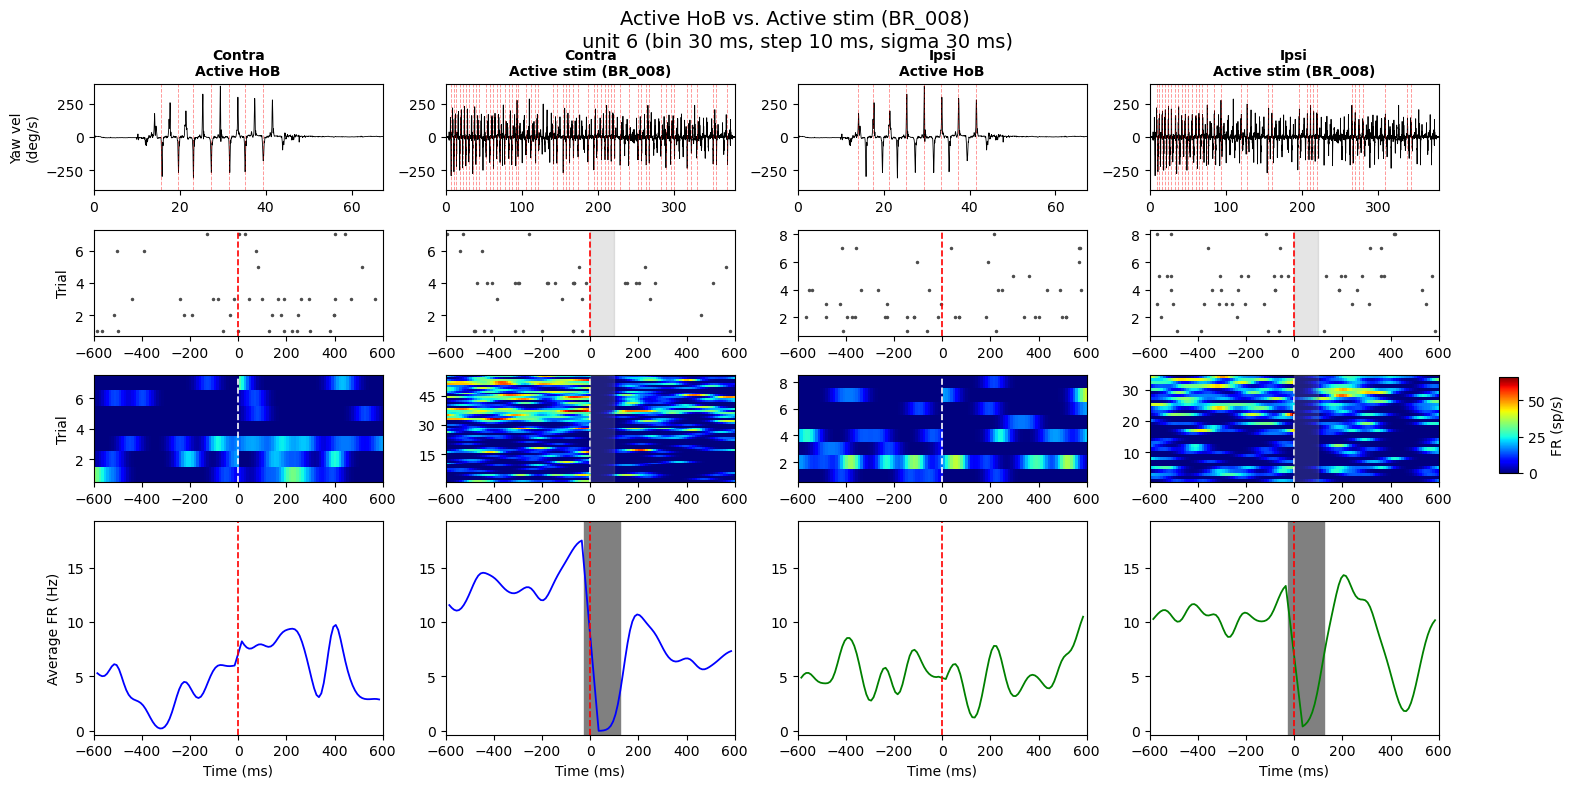

In [988]:
from matplotlib.ticker import MaxNLocator
# Plot ONE unit inline: contra and ipsi columns SIDE BY SIDE in one figure.
# Rows: 0 velocity trace, 1 raster (capped), 2 FR heatmap (all trials), 3 mean PSTH.
# Columns: [direction x condition], e.g. Contra-Passive, Contra-Active, Ipsi-Passive, Ipsi-Active.
# Y-axes and heatmap color scale locked per row across ALL columns for comparability.

plot_conds = [cond for cond in CONDITIONS if cond["label"] in ("Active HoB", "Active stim (BR_008)")]
assert plot_conds, "plot_conds is empty — check the labels match CONDITIONS exactly"

n_contra = min(cond_cache[cond["label"]]["events"]["contra"].size for cond in plot_conds)
n_ipsi   = min(cond_cache[cond["label"]]["events"]["ipsi"].size   for cond in plot_conds)
print(f"trial cap: contra n={n_contra}, ipsi n={n_ipsi}")

directions = [
    ("Contra", "contra", n_contra, "b"),
    ("Ipsi",   "ipsi",   n_ipsi,   "g"),
]

# One column per (direction, condition) pair, ordered direction-major.
columns = []
for dir_label, dir_key, n_cap, color in directions:
    for cond in plot_conds:
        columns.append(dict(dir_label=dir_label, dir_key=dir_key, n_cap=n_cap,
                            color=color, cond=cond))

n_cols = len(columns)
n_cap_raster = max(n_contra, n_ipsi)  # raster row height fits the larger cap

fig, axes = plt.subplots(
    4, n_cols, figsize=(4 * n_cols, 8), squeeze=False,
    gridspec_kw={"height_ratios": [1, 1, 1, 2]},  # vel, raster, heatmap, PSTH
)
last_im = None

# --- Pass 1: compute per-column data and track shared ranges (across all columns) ---
col_data = []
psth_max = 0.0
vel_absmax = 0.0
heat_max = 0.0
for col in columns:
    cc = cond_cache[col["cond"]["label"]]
    spk_s = aligned_spikes[cond["label"]].get(uid, np.zeros(0))
    events_full = cc["events"][col["dir_key"]]
    events_rast = events_full[:col["n_cap"]]
    msb, tail = (0.0, 0.0) if cc["kind"] == "baseline" else (STIM_MS_BEFORE, STIM_TAIL_MS)

    rates, rel_s = get_gaussian_rates(spk_s, events_full, msb, tail)  # [n_trials, n_bins]
    psth = np.nanmean(rates, axis=0) if rates.size else np.zeros(0)
    if psth.size:
        psth_max = max(psth_max, np.nanmax(psth))
    if rates.size:
        heat_max = max(heat_max, np.nanmax(rates))
    if cc["vel"].size:
        vel_absmax = max(vel_absmax, np.nanmax(np.abs(cc["vel"])))

    col_data.append(dict(col=col, cc=cc, spk_s=spk_s, events_full=events_full,
                         events_rast=events_rast, rel_s=rel_s, rates=rates, psth=psth))

# locked limits for the whole figure
psth_ylim = (min(0.0, -0.02 * psth_max), psth_max * 1.1 if psth_max > 0 else 1.0)
vel_ylim = (-vel_absmax * 1.05, vel_absmax * 1.05) if vel_absmax > 0 else (-500, 500)
heat_vmax = heat_max if heat_max > 0 else 1.0

# --- Pass 2: plot with locked axes ---
for c, d in enumerate(col_data):
    cc = d["cc"]
    col = d["col"]
    label = f"{col['dir_label']}\n{col['cond']['label']}"

    # Row 0: velocity trace + all event markers (locked y)
    ax_vel = axes[0][c]
    ax_vel.plot(cc["t_vel"], cc["vel"], color="k", lw=0.6)
    ax_vel.set_ylim(vel_ylim)
    ax_vel.set_xlim(0, cc["t_vel"][-1] if cc["t_vel"].size else 1)
    ax_vel.set_title(label, fontsize=10, fontweight="bold")
    if c == 0:
        ax_vel.set_ylabel("Yaw vel\n(deg/s)")
    for p in d["events_full"]:
        ax_vel.axvline(p, color="r", ls="--", alpha=0.4, lw=0.7)

    # Row 1: raster (capped)
    ax_raster = axes[1][c]
    for trial, t0 in enumerate(d["events_rast"]):
        in_win = (d["spk_s"] >= t0 - WIN_PRE_S) & (d["spk_s"] <= t0 + WIN_POST_S)
        rel_ms = (d["spk_s"][in_win] - t0) * 1000.0
        ax_raster.plot(rel_ms, np.full(rel_ms.size, trial + 1), ".",
                       color=[0.3, 0.3, 0.3], markersize=3)
    ax_raster.axvline(0, color="r", ls="--", lw=1.2)
    if cc["kind"] == "stim":
        ax_raster.axvspan(0, 100, color="grey", alpha=0.2, zorder=0)  # stim period
    ax_raster.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
    ax_raster.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
    if c == 0:
        ax_raster.set_ylabel("Trial")

    # Row 2: FR heatmap, all trials (locked jet color scale)
    ax_heat = axes[2][c]
    if d["rates"].size:
        extent = [-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0, 0.5, d["rates"].shape[0] + 0.5]
        im = ax_heat.imshow(d["rates"], aspect="auto", cmap="jet",
                            vmin=0, vmax=heat_vmax, extent=extent,
                            interpolation="nearest", origin="lower")
        last_im = im
    ax_heat.axvline(0, color="w", ls="--", lw=1.2)
    if cc["kind"] == "stim":
        ax_heat.axvspan(0, 100, color="grey", alpha=0.25, zorder=3)  # stim period (over image)
    ax_heat.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
    ax_heat.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
    if c == 0:
        ax_heat.set_ylabel("Trial")

    # Row 3: mean PSTH (y locked)
    ax_psth = axes[3][c]
    if d["psth"].size:
        ax_psth.plot(d["rel_s"] * 1000.0, d["psth"], color=col["color"], lw=1.3)
    ax_psth.axvline(0, color="r", ls="--", lw=1.2)
    if cc["kind"] == "stim":
        ax_psth.axvspan(-25, 125, color="grey", alpha=1, zorder=0)  # stim period
    ax_psth.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
    ax_psth.set_ylim(psth_ylim)
    if c == 0:
        ax_psth.set_ylabel("Average FR (Hz)")
    ax_psth.set_xlabel("Time (ms)")

fig.tight_layout(rect=[0, 0, 0.92, 0.95])
if last_im is not None:
    cbar_ax = fig.add_axes([0.94, 0.4, 0.012, 0.12])
    fig.colorbar(last_im, cax=cbar_ax, label="FR (sp/s)")

cond_title = " vs. ".join(c["label"] for c in plot_conds)
fig.suptitle(
    f"{cond_title}\n unit {uid} (bin {BIN_MS:.0f} ms, step {STEP_MS:.0f} ms, sigma {SIGMA_MS:.0f} ms)",
    fontsize=14,
)
plt.show()

# Batch Passive vs Active

In [989]:
# Batch-save all units to PNG
from matplotlib.ticker import MaxNLocator

# Batch-save one PNG per unit: contra & ipsi columns side by side.
plot_conds = [cond for cond in CONDITIONS if cond["label"] in ("Passive HoB", "Active HoB")]
assert plot_conds, "plot_conds is empty — check the labels match CONDITIONS exactly"

n_contra = min(cond_cache[cond["label"]]["events"]["contra"].size for cond in plot_conds)
n_ipsi   = min(cond_cache[cond["label"]]["events"]["ipsi"].size   for cond in plot_conds)
print(f"trial cap: contra n={n_contra}, ipsi n={n_ipsi}")

directions = [
    ("Contra", "contra", n_contra, "b"),
    ("Ipsi",   "ipsi",   n_ipsi,   "g"),
]

columns = []
for dir_label, dir_key, n_cap, color in directions:
    for cond in plot_conds:
        columns.append(dict(dir_label=dir_label, dir_key=dir_key, n_cap=n_cap,
                            color=color, cond=cond))

n_cols = len(columns)
n_cap_raster = max(n_contra, n_ipsi)

# Output dir keyed by the conditions being compared, so batches don't overwrite each other
cond_tag = "_vs_".join(c["label"].replace(" ", "").replace("(", "").replace(")", "") for c in plot_conds)
batch_dir = OUT_FIG_DIR / cond_tag
batch_dir.mkdir(parents=True, exist_ok=True)

units_to_save = available_units  # or a custom list, e.g. [6, 31, 54, 77]
print(f"Saving {len(units_to_save)} units to {batch_dir}")

for uid in units_to_save:
    fig, axes = plt.subplots(
        4, n_cols, figsize=(4 * n_cols, 8), squeeze=False,
        gridspec_kw={"height_ratios": [1, 1, 1, 2]},
    )
    last_im = None

    # --- Pass 1: compute per-column data and track shared ranges ---
    col_data = []
    psth_max = 0.0
    vel_absmax = 0.0
    heat_max = 0.0
    for col in columns:
        cc = cond_cache[col["cond"]["label"]]
        spk_s = aligned_spikes[cond["label"]].get(uid, np.zeros(0))
        events_full = cc["events"][col["dir_key"]]
        events_rast = events_full[:col["n_cap"]]
        msb, tail = (0.0, 0.0) if cc["kind"] == "baseline" else (STIM_MS_BEFORE, STIM_TAIL_MS)

        rates, rel_s = get_gaussian_rates(spk_s, events_full, msb, tail)
        psth = np.nanmean(rates, axis=0) if rates.size else np.zeros(0)
        if psth.size:
            psth_max = max(psth_max, np.nanmax(psth))
        if rates.size:
            heat_max = max(heat_max, np.nanmax(rates))
        if cc["vel"].size:
            vel_absmax = max(vel_absmax, np.nanmax(np.abs(cc["vel"])))

        col_data.append(dict(col=col, cc=cc, spk_s=spk_s, events_full=events_full,
                             events_rast=events_rast, rel_s=rel_s, rates=rates, psth=psth))

    psth_ylim = (min(0.0, -0.02 * psth_max), psth_max * 1.1 if psth_max > 0 else 1.0)
    vel_ylim = (-vel_absmax * 1.05, vel_absmax * 1.05) if vel_absmax > 0 else (-500, 500)
    heat_vmax = heat_max if heat_max > 0 else 1.0

    # --- Pass 2: plot with locked axes ---
    for c, d in enumerate(col_data):
        cc = d["cc"]
        col = d["col"]
        label = f"{col['dir_label']}\n{col['cond']['label']}"

        ax_vel = axes[0][c]
        ax_vel.plot(cc["t_vel"], cc["vel"], color="k", lw=0.6)
        ax_vel.set_ylim(vel_ylim)
        ax_vel.set_xlim(0, cc["t_vel"][-1] if cc["t_vel"].size else 1)
        ax_vel.set_title(label, fontsize=10, fontweight="bold")
        if c == 0:
            ax_vel.set_ylabel("Yaw vel\n(deg/s)")
        for p in d["events_full"]:
            ax_vel.axvline(p, color="r", ls="--", alpha=0.4, lw=0.7)

        ax_raster = axes[1][c]
        for trial, t0 in enumerate(d["events_rast"]):
            in_win = (d["spk_s"] >= t0 - WIN_PRE_S) & (d["spk_s"] <= t0 + WIN_POST_S)
            rel_ms = (d["spk_s"][in_win] - t0) * 1000.0
            ax_raster.plot(rel_ms, np.full(rel_ms.size, trial + 1), ".",
                           color=[0.3, 0.3, 0.3], markersize=3)
        ax_raster.axvline(0, color="r", ls="--", lw=1.2)
        if cc["kind"] == "stim":
            ax_raster.axvspan(0, 100, color="grey", alpha=0.2, zorder=0)
        ax_raster.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
        ax_raster.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
        if c == 0:
            ax_raster.set_ylabel("Trial")

        ax_heat = axes[2][c]
        if d["rates"].size:
            extent = [-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0, 0.5, d["rates"].shape[0] + 0.5]
            im = ax_heat.imshow(d["rates"], aspect="auto", cmap="jet",
                                vmin=0, vmax=heat_vmax, extent=extent,
                                interpolation="nearest", origin="lower")
            last_im = im
        ax_heat.axvline(0, color="w", ls="--", lw=1.2)
        if cc["kind"] == "stim":
            ax_heat.axvspan(0, 100, color="grey", alpha=0.25, zorder=3)
        ax_heat.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
        ax_heat.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
        if c == 0:
            ax_heat.set_ylabel("Trial")

        ax_psth = axes[3][c]
        if d["psth"].size:
            ax_psth.plot(d["rel_s"] * 1000.0, d["psth"], color=col["color"], lw=1.3)
        ax_psth.axvline(0, color="r", ls="--", lw=1.2)
        if cc["kind"] == "stim":
            ax_psth.axvspan(-25, 125, color="grey", alpha=1, zorder=0)
        ax_psth.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
        ax_psth.set_ylim(psth_ylim)
        if c == 0:
            ax_psth.set_ylabel("Average FR (Hz)")
        ax_psth.set_xlabel("Time (ms)")

    fig.tight_layout(rect=[0, 0, 0.92, 0.95])
    if last_im is not None:
        cbar_ax = fig.add_axes([0.94, 0.4, 0.012, 0.12])
        fig.colorbar(last_im, cax=cbar_ax, label="FR (sp/s)")

    cond_title = " vs. ".join(c["label"] for c in plot_conds)
    fig.suptitle(
        f"{cond_title}\n unit {uid} (bin {BIN_MS:.0f} ms, step {STEP_MS:.0f} ms, sigma {SIGMA_MS:.0f} ms)",
        fontsize=14,
    )
    fig.savefig(batch_dir / f"unit_{uid:03d}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    print(f"saved unit {uid}")

print(f"Done — {len(units_to_save)} figures in {batch_dir}")

trial cap: contra n=7, ipsi n=8
Saving 140 units to /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/PassiveHoB_vs_ActiveHoB
saved unit 6
saved unit 7
saved unit 8
saved unit 10
saved unit 11
saved unit 24
saved unit 28
saved unit 31
saved unit 37
saved unit 39
saved unit 40
saved unit 41
saved unit 43
saved unit 44
saved unit 46
saved unit 47
saved unit 48
saved unit 50
saved unit 52
saved unit 53
saved unit 54
saved unit 56
saved unit 58
saved unit 59
saved unit 60
saved unit 61
saved unit 62
saved unit 65
saved unit 66
saved unit 67
saved unit 68
saved unit 69
saved unit 71
saved unit 72
saved unit 73
saved unit 75
saved unit 77
saved unit 78
saved unit 79
saved unit 80
saved unit 81
saved unit 82
saved unit 83
saved unit 84
saved unit 86
saved unit 88
saved unit 89
saved unit 92
saved unit 94
saved unit 95
saved unit 96
saved unit 97
saved unit 98
saved unit 100
saved unit 103
sa

# Batch active vs active stim

trial cap: contra n=7, ipsi n=8
Saving 140 units to /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/ActiveHoB_vs_ActivestimBR_008
saved unit 6
saved unit 7
saved unit 8


KeyboardInterrupt: 

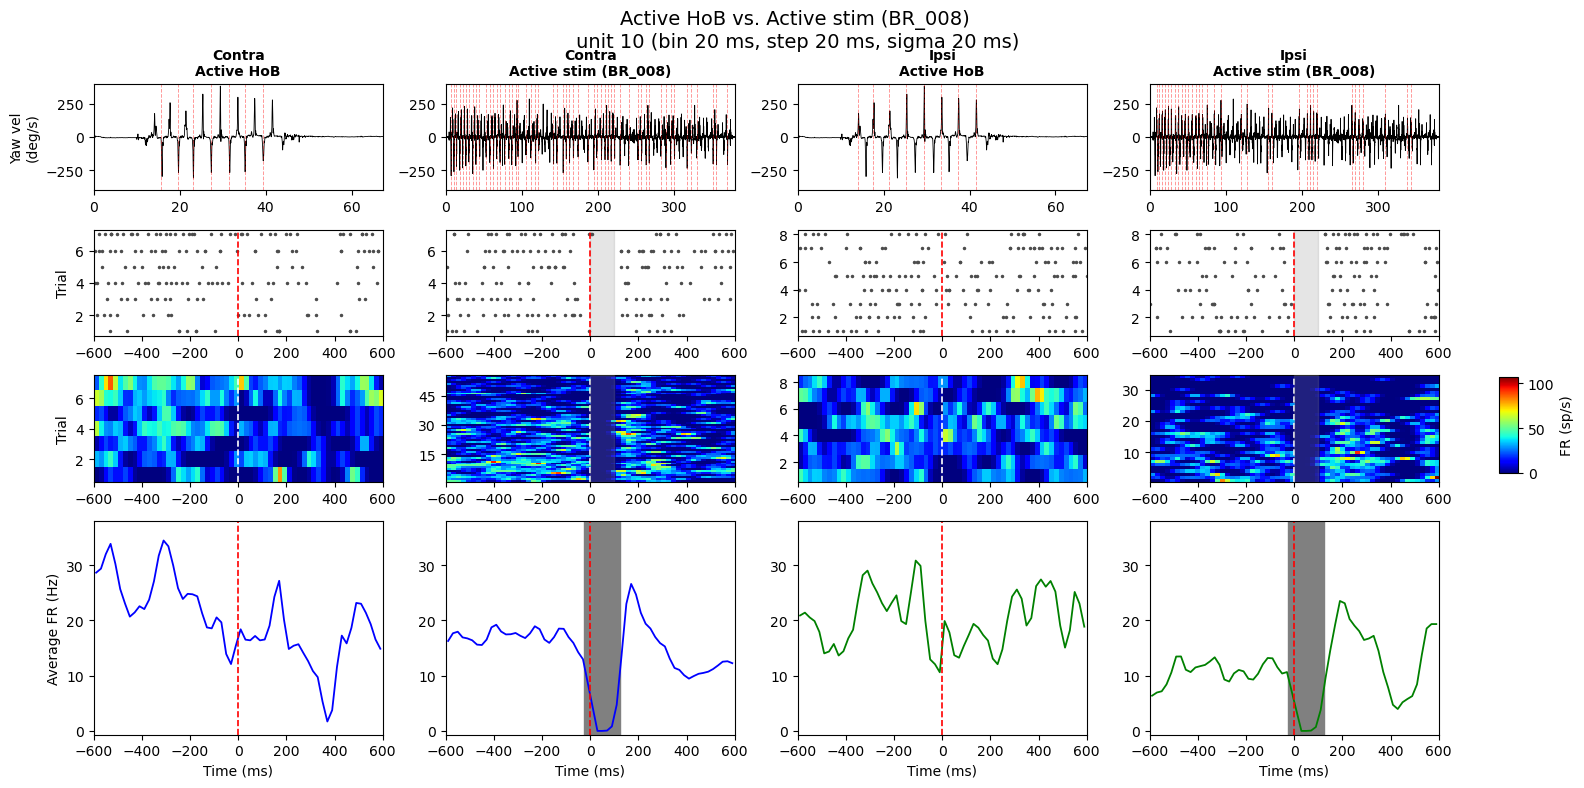

In [964]:
# Batch-save all units to PNG
from matplotlib.ticker import MaxNLocator

# Batch-save one PNG per unit: contra & ipsi columns side by side.
plot_conds = [cond for cond in CONDITIONS if cond["label"] in ("Active HoB", "Active stim (BR_008)")]
assert plot_conds, "plot_conds is empty — check the labels match CONDITIONS exactly"

n_contra = min(cond_cache[cond["label"]]["events"]["contra"].size for cond in plot_conds)
n_ipsi   = min(cond_cache[cond["label"]]["events"]["ipsi"].size   for cond in plot_conds)
print(f"trial cap: contra n={n_contra}, ipsi n={n_ipsi}")

directions = [
    ("Contra", "contra", n_contra, "b"),
    ("Ipsi",   "ipsi",   n_ipsi,   "g"),
]

columns = []
for dir_label, dir_key, n_cap, color in directions:
    for cond in plot_conds:
        columns.append(dict(dir_label=dir_label, dir_key=dir_key, n_cap=n_cap,
                            color=color, cond=cond))

n_cols = len(columns)
n_cap_raster = max(n_contra, n_ipsi)

# Output dir keyed by the conditions being compared, so batches don't overwrite each other
cond_tag = "_vs_".join(c["label"].replace(" ", "").replace("(", "").replace(")", "") for c in plot_conds)
batch_dir = OUT_FIG_DIR / cond_tag
batch_dir.mkdir(parents=True, exist_ok=True)

units_to_save = available_units  # or a custom list, e.g. [6, 31, 54, 77]
print(f"Saving {len(units_to_save)} units to {batch_dir}")

for uid in units_to_save:
    fig, axes = plt.subplots(
        4, n_cols, figsize=(4 * n_cols, 8), squeeze=False,
        gridspec_kw={"height_ratios": [1, 1, 1, 2]},
    )
    last_im = None

    # --- Pass 1: compute per-column data and track shared ranges ---
    col_data = []
    psth_max = 0.0
    vel_absmax = 0.0
    heat_max = 0.0
    for col in columns:
        cc = cond_cache[col["cond"]["label"]]
        spk_s = aligned_spikes[cond["label"]].get(uid, np.zeros(0))
        events_full = cc["events"][col["dir_key"]]
        events_rast = events_full[:col["n_cap"]]
        msb, tail = (0.0, 0.0) if cc["kind"] == "baseline" else (STIM_MS_BEFORE, STIM_TAIL_MS)

        rates, rel_s = get_gaussian_rates(spk_s, events_full, msb, tail)
        psth = np.nanmean(rates, axis=0) if rates.size else np.zeros(0)
        if psth.size:
            psth_max = max(psth_max, np.nanmax(psth))
        if rates.size:
            heat_max = max(heat_max, np.nanmax(rates))
        if cc["vel"].size:
            vel_absmax = max(vel_absmax, np.nanmax(np.abs(cc["vel"])))

        col_data.append(dict(col=col, cc=cc, spk_s=spk_s, events_full=events_full,
                             events_rast=events_rast, rel_s=rel_s, rates=rates, psth=psth))

    psth_ylim = (min(0.0, -0.02 * psth_max), psth_max * 1.1 if psth_max > 0 else 1.0)
    vel_ylim = (-vel_absmax * 1.05, vel_absmax * 1.05) if vel_absmax > 0 else (-500, 500)
    heat_vmax = heat_max if heat_max > 0 else 1.0

    # --- Pass 2: plot with locked axes ---
    for c, d in enumerate(col_data):
        cc = d["cc"]
        col = d["col"]
        label = f"{col['dir_label']}\n{col['cond']['label']}"

        ax_vel = axes[0][c]
        ax_vel.plot(cc["t_vel"], cc["vel"], color="k", lw=0.6)
        ax_vel.set_ylim(vel_ylim)
        ax_vel.set_xlim(0, cc["t_vel"][-1] if cc["t_vel"].size else 1)
        ax_vel.set_title(label, fontsize=10, fontweight="bold")
        if c == 0:
            ax_vel.set_ylabel("Yaw vel\n(deg/s)")
        for p in d["events_full"]:
            ax_vel.axvline(p, color="r", ls="--", alpha=0.4, lw=0.7)

        ax_raster = axes[1][c]
        for trial, t0 in enumerate(d["events_rast"]):
            in_win = (d["spk_s"] >= t0 - WIN_PRE_S) & (d["spk_s"] <= t0 + WIN_POST_S)
            rel_ms = (d["spk_s"][in_win] - t0) * 1000.0
            ax_raster.plot(rel_ms, np.full(rel_ms.size, trial + 1), ".",
                           color=[0.3, 0.3, 0.3], markersize=3)
        ax_raster.axvline(0, color="r", ls="--", lw=1.2)
        if cc["kind"] == "stim":
            ax_raster.axvspan(0, 100, color="grey", alpha=0.2, zorder=0)
        ax_raster.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
        ax_raster.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
        if c == 0:
            ax_raster.set_ylabel("Trial")

        ax_heat = axes[2][c]
        if d["rates"].size:
            extent = [-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0, 0.5, d["rates"].shape[0] + 0.5]
            im = ax_heat.imshow(d["rates"], aspect="auto", cmap="jet",
                                vmin=0, vmax=heat_vmax, extent=extent,
                                interpolation="nearest", origin="lower")
            last_im = im
        ax_heat.axvline(0, color="w", ls="--", lw=1.2)
        if cc["kind"] == "stim":
            ax_heat.axvspan(0, 100, color="grey", alpha=0.25, zorder=3)
        ax_heat.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
        ax_heat.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
        if c == 0:
            ax_heat.set_ylabel("Trial")

        ax_psth = axes[3][c]
        if d["psth"].size:
            ax_psth.plot(d["rel_s"] * 1000.0, d["psth"], color=col["color"], lw=1.3)
        ax_psth.axvline(0, color="r", ls="--", lw=1.2)
        if cc["kind"] == "stim":
            ax_psth.axvspan(-25, 125, color="grey", alpha=1, zorder=0)
        ax_psth.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
        ax_psth.set_ylim(psth_ylim)
        if c == 0:
            ax_psth.set_ylabel("Average FR (Hz)")
        ax_psth.set_xlabel("Time (ms)")

    fig.tight_layout(rect=[0, 0, 0.92, 0.95])
    if last_im is not None:
        cbar_ax = fig.add_axes([0.94, 0.4, 0.012, 0.12])
        fig.colorbar(last_im, cax=cbar_ax, label="FR (sp/s)")

    cond_title = " vs. ".join(c["label"] for c in plot_conds)
    fig.suptitle(
        f"{cond_title}\n unit {uid} (bin {BIN_MS:.0f} ms, step {STEP_MS:.0f} ms, sigma {SIGMA_MS:.0f} ms)",
        fontsize=14,
    )
    fig.savefig(batch_dir / f"unit_{uid:03d}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    print(f"saved unit {uid}")

print(f"Done — {len(units_to_save)} figures in {batch_dir}")

# Increase bin size

In [995]:
# Batch-save all units to PNG
from matplotlib.ticker import MaxNLocator

# Batch-save one PNG per unit: contra & ipsi columns side by side.
plot_conds = [cond for cond in CONDITIONS if cond["label"] in ("Active HoB", "Active stim (BR_008)")]
assert plot_conds, "plot_conds is empty — check the labels match CONDITIONS exactly"

n_contra = min(cond_cache[cond["label"]]["events"]["contra"].size for cond in plot_conds)
n_ipsi   = min(cond_cache[cond["label"]]["events"]["ipsi"].size   for cond in plot_conds)
print(f"trial cap: contra n={n_contra}, ipsi n={n_ipsi}")

directions = [
    ("Contra", "contra", n_contra, "b"),
    ("Ipsi",   "ipsi",   n_ipsi,   "g"),
]

columns = []
for dir_label, dir_key, n_cap, color in directions:
    for cond in plot_conds:
        columns.append(dict(dir_label=dir_label, dir_key=dir_key, n_cap=n_cap,
                            color=color, cond=cond))

n_cols = len(columns)
n_cap_raster = max(n_contra, n_ipsi)

# Output dir keyed by the conditions being compared, so batches don't overwrite each other
cond_tag = "_vs_".join(c["label"].replace(" ", "").replace("(", "").replace(")", "") for c in plot_conds)
param_tag = f"bin{BIN_MS:.0f}_step{STEP_MS:.0f}_sigma{SIGMA_MS:.0f}ms"
batch_dir = OUT_FIG_DIR / f"{cond_tag}__{param_tag}"
batch_dir.mkdir(parents=True, exist_ok=True)

units_to_save = available_units  # or a custom list, e.g. [6, 31, 54, 77]
print(f"Saving {len(units_to_save)} units to {batch_dir}")

for uid in units_to_save:
    fig, axes = plt.subplots(
        4, n_cols, figsize=(4 * n_cols, 8), squeeze=False,
        gridspec_kw={"height_ratios": [1, 1, 1, 2]},
    )
    last_im = None

    # --- Pass 1: compute per-column data and track shared ranges ---
    col_data = []
    psth_max = 0.0
    vel_absmax = 0.0
    heat_max = 0.0
    for col in columns:
        cc = cond_cache[col["cond"]["label"]]
        spk_s = aligned_spikes[cond["label"]].get(uid, np.zeros(0))
        events_full = cc["events"][col["dir_key"]]
        events_rast = events_full[:col["n_cap"]]
        msb, tail = (0.0, 0.0) if cc["kind"] == "baseline" else (STIM_MS_BEFORE, STIM_TAIL_MS)

        rates, rel_s = get_gaussian_rates(spk_s, events_full, msb, tail)
        psth = np.nanmean(rates, axis=0) if rates.size else np.zeros(0)
        if psth.size:
            psth_max = max(psth_max, np.nanmax(psth))
        if rates.size:
            heat_max = max(heat_max, np.nanmax(rates))
        if cc["vel"].size:
            vel_absmax = max(vel_absmax, np.nanmax(np.abs(cc["vel"])))

        col_data.append(dict(col=col, cc=cc, spk_s=spk_s, events_full=events_full,
                             events_rast=events_rast, rel_s=rel_s, rates=rates, psth=psth))

    psth_ylim = (min(0.0, -0.02 * psth_max), psth_max * 1.1 if psth_max > 0 else 1.0)
    vel_ylim = (-vel_absmax * 1.05, vel_absmax * 1.05) if vel_absmax > 0 else (-500, 500)
    heat_vmax = heat_max if heat_max > 0 else 1.0

    # --- Pass 2: plot with locked axes ---
    for c, d in enumerate(col_data):
        cc = d["cc"]
        col = d["col"]
        label = f"{col['dir_label']}\n{col['cond']['label']}"

        ax_vel = axes[0][c]
        ax_vel.plot(cc["t_vel"], cc["vel"], color="k", lw=0.6)
        ax_vel.set_ylim(vel_ylim)
        ax_vel.set_xlim(0, cc["t_vel"][-1] if cc["t_vel"].size else 1)
        ax_vel.set_title(label, fontsize=10, fontweight="bold")
        if c == 0:
            ax_vel.set_ylabel("Yaw vel\n(deg/s)")
        for p in d["events_full"]:
            ax_vel.axvline(p, color="r", ls="--", alpha=0.4, lw=0.7)

        ax_raster = axes[1][c]
        for trial, t0 in enumerate(d["events_rast"]):
            in_win = (d["spk_s"] >= t0 - WIN_PRE_S) & (d["spk_s"] <= t0 + WIN_POST_S)
            rel_ms = (d["spk_s"][in_win] - t0) * 1000.0
            ax_raster.plot(rel_ms, np.full(rel_ms.size, trial + 1), ".",
                           color=[0.3, 0.3, 0.3], markersize=3)
        ax_raster.axvline(0, color="r", ls="--", lw=1.2)
        if cc["kind"] == "stim":
            ax_raster.axvspan(0, 100, color="grey", alpha=0.2, zorder=0)
        ax_raster.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
        ax_raster.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
        if c == 0:
            ax_raster.set_ylabel("Trial")

        ax_heat = axes[2][c]
        if d["rates"].size:
            extent = [-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0, 0.5, d["rates"].shape[0] + 0.5]
            im = ax_heat.imshow(d["rates"], aspect="auto", cmap="jet",
                                vmin=0, vmax=heat_vmax, extent=extent,
                                interpolation="nearest", origin="lower")
            last_im = im
        ax_heat.axvline(0, color="w", ls="--", lw=1.2)
        if cc["kind"] == "stim":
            ax_heat.axvspan(0, 100, color="grey", alpha=0.25, zorder=3)
        ax_heat.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
        ax_heat.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
        if c == 0:
            ax_heat.set_ylabel("Trial")

        ax_psth = axes[3][c]
        if d["psth"].size:
            ax_psth.plot(d["rel_s"] * 1000.0, d["psth"], color=col["color"], lw=1.3)
        ax_psth.axvline(0, color="r", ls="--", lw=1.2)
        if cc["kind"] == "stim":
            ax_psth.axvspan(-25, 125, color="grey", alpha=1, zorder=0)
        ax_psth.set_xlim(-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)
        ax_psth.set_ylim(psth_ylim)
        if c == 0:
            ax_psth.set_ylabel("Average FR (Hz)")
        ax_psth.set_xlabel("Time (ms)")

    fig.tight_layout(rect=[0, 0, 0.92, 0.95])
    if last_im is not None:
        cbar_ax = fig.add_axes([0.94, 0.4, 0.012, 0.12])
        fig.colorbar(last_im, cax=cbar_ax, label="FR (sp/s)")

    cond_title = " vs. ".join(c["label"] for c in plot_conds)
    fig.suptitle(
        f"{cond_title}\n unit {uid} (bin {BIN_MS:.0f} ms, step {STEP_MS:.0f} ms, sigma {SIGMA_MS:.0f} ms)",
        fontsize=14,
    )
    fig.savefig(batch_dir / f"unit_{uid:03d}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    print(f"saved unit {uid}")

print(f"Done — {len(units_to_save)} figures in {batch_dir}")

trial cap: contra n=7, ipsi n=8
Saving 140 units to /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/figures/per_unit_cross_condition/ActiveHoB_vs_ActivestimBR_008__bin30_step10_sigma30ms
saved unit 6
saved unit 7
saved unit 8
saved unit 10
saved unit 11
saved unit 24
saved unit 28
saved unit 31
saved unit 37
saved unit 39
saved unit 40
saved unit 41
saved unit 43
saved unit 44
saved unit 46
saved unit 47
saved unit 48
saved unit 50
saved unit 52
saved unit 53
saved unit 54
saved unit 56
saved unit 58
saved unit 59
saved unit 60
saved unit 61
saved unit 62
saved unit 65
saved unit 66
saved unit 67
saved unit 68
saved unit 69
saved unit 71
saved unit 72
saved unit 73
saved unit 75
saved unit 77
saved unit 78
saved unit 79
saved unit 80
saved unit 81
saved unit 82
saved unit 83
saved unit 84
saved unit 86
saved unit 88
saved unit 89
saved unit 92
saved unit 94
saved unit 95
saved unit 96
saved unit 97
saved unit 98
sa

# Aggregate and plot neuron x time

TypeError: Dimensions of C (110, 116) should be one smaller than X(116) and Y(111) while using shading='flat' see help(pcolormesh)

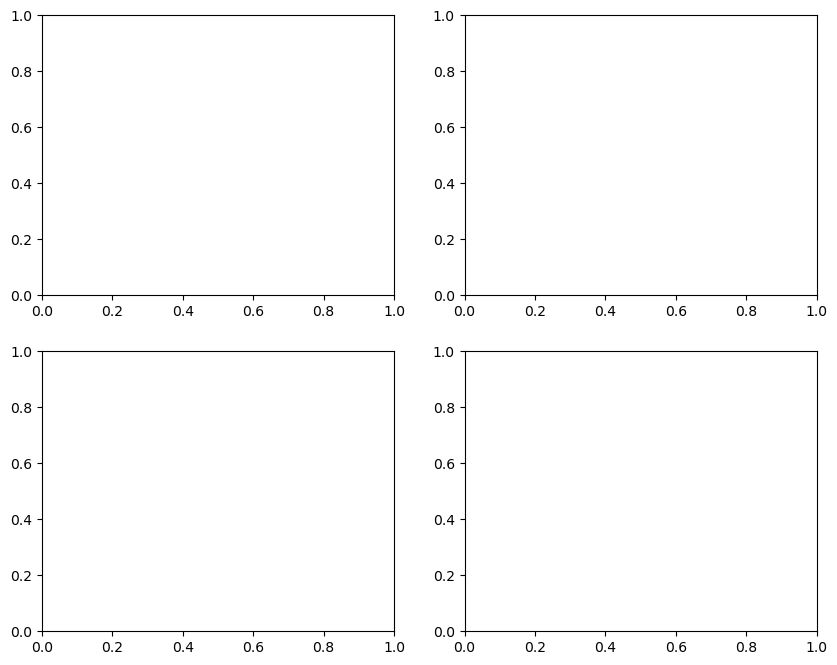

In [1000]:
from matplotlib.ticker import MaxNLocator

# Population heatmap: neuron x time, peak-normalized FR (0-1), 'bone', active vs active stim.
# Each unit normalized by its own peak across both conditions (per direction).
# Each figure ROW ordered by PRE-STIM peak in the FIRST column.

pop_units_input = [6, 8, 10, 24, 31, 40, 43, 44, 50, 52, 53, 54, 56, 58, 59, 60, 61, 65, 66, 67, 68, 71, 72, 73, 75, 77, 79, 80, 81, 83, 84, 88, 89, 92, 94, 95, 96, 97, 98, 100, 103, 104, 105, 107, 108, 109, 110, 111, 112, 113, 114, 117, 119, 120, 121, 122, 123, 125, 126, 127, 128, 129, 130, 131, 132, 134, 135, 136, 137, 143, 146, 147, 149, 150, 151, 152, 154, 155, 156, 158, 159, 162, 163, 164, 165, 166, 171, 172, 174, 175, 176, 179, 180, 181, 182, 184, 186, 187, 188, 190, 191, 194, 199, 200, 201, 203, 206, 210, 215, 218]

plot_conds = [cond for cond in CONDITIONS if cond["label"] in ("Passive HoB", "Active HoB")]
assert plot_conds, "plot_conds is empty — check the labels match CONDITIONS exactly"

directions = [("Contra", "contra"), ("Ipsi", "ipsi")]

CMAP = "bone"
ORDER_COND = plot_conds[1]["label"]        # active condition (left column) sets order
ORDER_WINDOW_MS = (0.0, 200.0)             # rank by peak in 0-300 ms post-stim
PRE_WINDOW_MS = (-WIN_PRE_S * 1000.0, 0.0)   # rank by peak in the pre-stim window

# --- Build raw population matrices (input unit order) ---
pop_raw = {}
rel_s_ref = None
rel_s_by_cond = {}
for dir_label, dir_key in directions:
    pop_raw[dir_label] = {}
    for cond in plot_conds:
        cc = cond_cache[cond["label"]]
        events = cc["events"][dir_key]
        msb, tail = (0.0, 0.0) if cc["kind"] == "baseline" else (STIM_MS_BEFORE, STIM_TAIL_MS)
        rows = []
        for uid in pop_units_input:
            spk_s = aligned_spikes[cond["label"]].get(uid, np.zeros(0))
            rates, rel_s = get_gaussian_rates(spk_s, events, msb, tail)
            psth = np.nanmean(rates, axis=0) if rates.size else np.full(rel_s.size, np.nan)
            rows.append(psth)
            if rel_s_ref is None and rel_s.size:
                rel_s_ref = rel_s
        rel_s_by_cond[cond["label"]] = rel_s
        pop_raw[dir_label][cond["label"]] = np.vstack(rows)  # (n_units, n_time)

# --- Peak-normalize each unit (0-1) SEPARATELY per condition (per direction) ---
pop_norm = {}
cond_labels = [c["label"] for c in plot_conds]
for dir_label in pop_raw:
    pop_norm[dir_label] = {}
    for cl in cond_labels:
        mat = pop_raw[dir_label][cl]
        peak = np.nanmax(mat, axis=1, keepdims=True)  # this condition's own per-unit peak
        peak[peak < 1e-9] = 1.0                        # guard silent units
        pop_norm[dir_label][cl] = mat / peak

# --- Per-direction row order by PRE-STIM peak in the first column ---
# --- Per-direction row order by peak in 0-300 ms in the active condition ---
rel_ms_order = rel_s_by_cond[ORDER_COND] * 1000.0
order_mask = (rel_ms_order >= ORDER_WINDOW_MS[0]) & (rel_ms_order <= ORDER_WINDOW_MS[1])

pop_data = {}
row_units = {}
for dir_label in pop_norm:
    ref_mat = pop_norm[dir_label][ORDER_COND]
    peak = np.nanmax(ref_mat[:, order_mask], axis=1)   # peak in 0-300 ms
    peak = np.where(np.isfinite(peak), peak, -np.inf)
    order = np.argsort(peak)[::-1]                      # highest at top
    pop_data[dir_label] = {cl: pop_norm[dir_label][cl][order] for cl in cond_labels}
    row_units[dir_label] = [pop_units_input[i] for i in order]

# --- Shared color scale (0-1, since peak-normalized) ---
vmin, vmax = 0.0, 1.0

# --- Plot ---
n_cond = len(plot_conds)
rel_ms = rel_s_ref * 1000.0
n_units = len(pop_units_input)
extent = [rel_ms[0], rel_ms[-1], n_units - 0.5, -0.5]

fig, axes = plt.subplots(len(directions), n_cond, figsize=(5 * n_cond, 4 * len(directions)),
                         squeeze=False)
last_im = None
for r, (dir_label, dir_key) in enumerate(directions):
    for cnd, cond in enumerate(plot_conds):
        ax = axes[r][cnd]
        mat = pop_data[dir_label][cond["label"]]
        cond_rel_ms = rel_s_by_cond[cond["label"]] * 1000.0

        # reindex this panel's columns onto the FULL (active) time grid, inserting
        # NaN where bins were blanked, so the gap renders as empty
        full_rel_ms = rel_ms  # active condition's full axis
        full_mat = np.full((mat.shape[0], full_rel_ms.size), np.nan)
        # match each of this panel's bin centers to the nearest full-grid bin
        col_idx = np.searchsorted(full_rel_ms, cond_rel_ms)
        col_idx = np.clip(col_idx, 0, full_rel_ms.size - 1)
        full_mat[:, col_idx] = mat

        im = ax.pcolormesh(full_rel_ms, np.arange(n_units + 1) - 0.5, full_mat,
                           cmap=CMAP, vmin=vmin, vmax=vmax, shading="flat")
        ax.set_ylim(n_units - 0.5, -0.5)  # keep unit 0 at top

fig.tight_layout(rect=[0, 0, 0.92, 0.92])
if last_im is not None:
    cbar_ax = fig.add_axes([0.94, 0.3, 0.012, 0.4])
    fig.colorbar(last_im, cax=cbar_ax, label="Norm. FR (per-column)")

fig.suptitle(
    f"Population FR (per-column normalized) — active vs active stim\n"
    f"(n={n_units} units, each row ordered by 0-300ms peak in {ORDER_COND},\n"
    f"bin {BIN_MS:.0f} ms, step {STEP_MS:.0f} ms, sigma {SIGMA_MS:.0f} ms",
    fontsize=12, y=0.98,
)
plt.show()

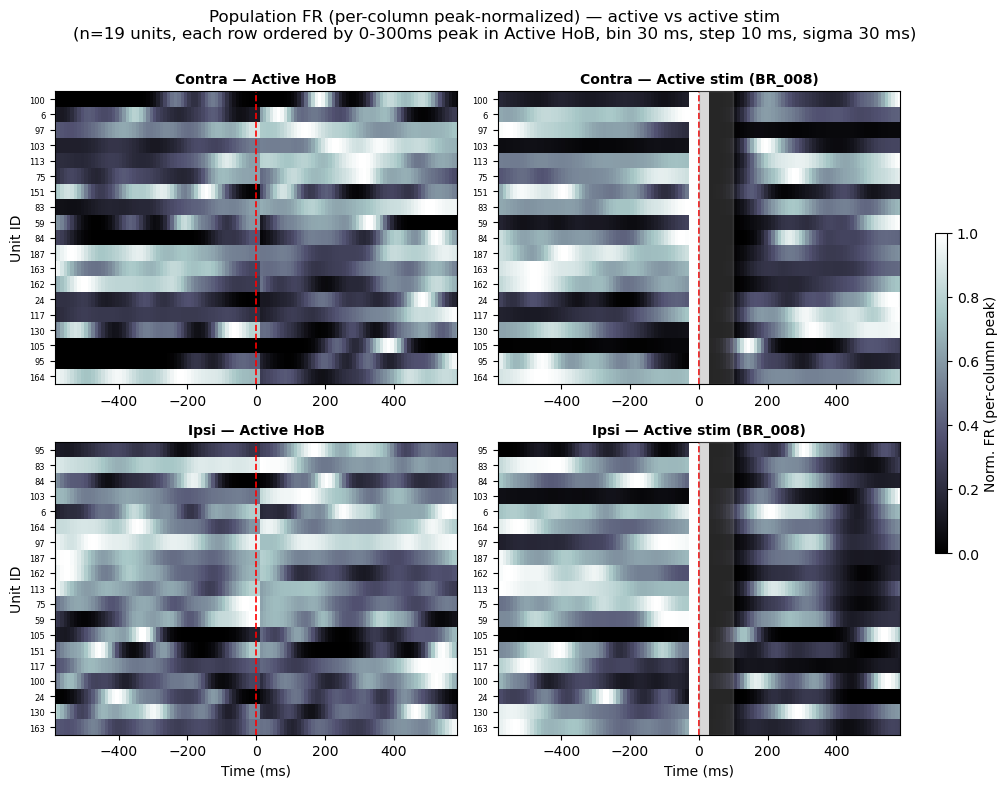

In [ ]:
from matplotlib.ticker import MaxNLocator

# Population heatmap: neuron x time, peak-normalized FR (0-1), 'bone', active vs active stim.
# Each unit normalized by its own peak across both conditions (per direction).
# Each figure ROW ordered by PRE-STIM peak in the FIRST column.

pop_units_input = [6, 59, 71, 75, 83, 84, 88, 97, 103, 105, 112, 113, 117, 130, 162, 163, 164, 187]

plot_conds = [cond for cond in CONDITIONS if cond["label"] in ("Active HoB", "Active stim (BR_008)")]
assert plot_conds, "plot_conds is empty — check the labels match CONDITIONS exactly"

directions = [("Contra", "contra"), ("Ipsi", "ipsi")]

CMAP = "bone"
ORDER_COND = plot_conds[0]["label"]        # active condition (left column) sets order
ORDER_WINDOW_MS = (0.0, 300.0)             # rank by peak in 0-300 ms post-stim
PRE_WINDOW_MS = (-WIN_PRE_S * 1000.0, 0.0)   # rank by peak in the pre-stim window

# --- Build raw population matrices (input unit order) ---
pop_raw = {}
rel_s_ref = None
rel_s_by_cond = {}
for dir_label, dir_key in directions:
    pop_raw[dir_label] = {}
    for cond in plot_conds:
        cc = cond_cache[cond["label"]]
        events = cc["events"][dir_key]
        msb, tail = (0.0, 0.0) if cc["kind"] == "baseline" else (STIM_MS_BEFORE, STIM_TAIL_MS)
        rows = []
        for uid in pop_units_input:
            spk_s = aligned_spikes[cond["label"]].get(uid, np.zeros(0))
            rates, rel_s = get_gaussian_rates(spk_s, events, msb, tail)
            psth = np.nanmean(rates, axis=0) if rates.size else np.full(rel_s.size, np.nan)
            rows.append(psth)
            if rel_s_ref is None and rel_s.size:
                rel_s_ref = rel_s
        rel_s_by_cond[cond["label"]] = rel_s
        pop_raw[dir_label][cond["label"]] = np.vstack(rows)  # (n_units, n_time)

# --- Peak-normalize each unit (0-1) using its max across both conditions (per direction) ---
pop_norm = {}
cond_labels = [c["label"] for c in plot_conds]
for dir_label in pop_raw:
    stacked = np.concatenate([pop_raw[dir_label][cl] for cl in cond_labels], axis=1)
    peak = np.nanmax(stacked, axis=1, keepdims=True)  # per-unit peak over both conditions
    peak[peak < 1e-9] = 1.0                            # guard silent units
    pop_norm[dir_label] = {cl: pop_raw[dir_label][cl] / peak for cl in cond_labels}

# --- Per-direction row order by PRE-STIM peak in the first column ---
# --- Per-direction row order by peak in 0-300 ms in the active condition ---
rel_ms_order = rel_s_by_cond[ORDER_COND] * 1000.0
order_mask = (rel_ms_order >= ORDER_WINDOW_MS[0]) & (rel_ms_order <= ORDER_WINDOW_MS[1])

pop_data = {}
row_units = {}
for dir_label in pop_norm:
    ref_mat = pop_norm[dir_label][ORDER_COND]
    peak = np.nanmax(ref_mat[:, order_mask], axis=1)   # peak in 0-300 ms
    peak = np.where(np.isfinite(peak), peak, -np.inf)
    order = np.argsort(peak)[::-1]                      # highest at top
    pop_data[dir_label] = {cl: pop_norm[dir_label][cl][order] for cl in cond_labels}
    row_units[dir_label] = [pop_units_input[i] for i in order]

# --- Shared color scale (0-1, since peak-normalized) ---
vmin, vmax = 0.0, 1.0

# --- Plot ---
n_cond = len(plot_conds)
rel_ms = rel_s_ref * 1000.0
n_units = len(pop_units_input)
extent = [rel_ms[0], rel_ms[-1], n_units - 0.5, -0.5]

fig, axes = plt.subplots(len(directions), n_cond, figsize=(5 * n_cond, 4 * len(directions)),
                         squeeze=False)
last_im = None
for r, (dir_label, dir_key) in enumerate(directions):
    for cnd, cond in enumerate(plot_conds):
        ax = axes[r][cnd]
        mat = pop_data[dir_label][cond["label"]]
        im = ax.imshow(mat, aspect="auto", cmap=CMAP, vmin=vmin, vmax=vmax,
                       extent=extent, interpolation="nearest")
        last_im = im
        ax.axvline(0, color="r", ls="--", lw=1.2)
        if cond["kind"] == "stim":
            ax.axvspan(0, 100, color="grey", alpha=1, zorder=3)  # stim period
        ax.set_xlim(rel_ms[0], rel_ms[-1])
        ax.set_yticks(range(n_units))
        ax.set_yticklabels(row_units[dir_label], fontsize=6)
        ax.set_title(f"{dir_label} — {cond['label']}", fontsize=10, fontweight="bold")
        if cnd == 0:
            ax.set_ylabel("Unit ID")
        if r == len(directions) - 1:
            ax.set_xlabel("Time (ms)")

fig.tight_layout(rect=[0, 0, 0.92, 0.92])
if last_im is not None:
    cbar_ax = fig.add_axes([0.94, 0.3, 0.012, 0.4])
    fig.colorbar(last_im, cax=cbar_ax, label="Norm. FR")

fig.suptitle(
    f"Population FR (peak-normalized) — Active vs Active stim\n"
    f"(n={n_units} units, each row ordered by 0-300ms peak in {ORDER_COND},\n"
    f"bin {BIN_MS:.0f} ms, step {STEP_MS:.0f} ms, sigma {SIGMA_MS:.0f} ms",
    fontsize=12, y=0.98,
)
plt.show()